# FAYE Marie Pierre Gnilane Ndew
# 12213642

# Introduction
En apprentissage automatique, la qualité d'un modèle dépend autant des données qu'on lui fournit que de l'algorithme lui-même. Les données brutes sont rarement prêtes à l'emploi : les variables peuvent être exprimées dans des unités différentes (un âge en années, un salaire en euros, une taille en mètres) et donc avoir des ordres de grandeur très différents. Or de nombreux algorithmes, comme les SVM avec noyau RBF, les modèles linéaires régularisés (L1, L2), les k plus proches voisins ou encore la descente de gradient, reposent sur des calculs de distances ou supposent que toutes les variables sont comparables. Une variable dont les valeurs sont beaucoup plus grandes que les autres risque alors de dominer la fonction objectif et d'empêcher le modèle d'apprendre correctement.
Pour corriger ce problème, on applique un prétraitement aux données. Le module sklearn.preprocessing de la bibliothèque scikit-learn propose plusieurs outils pour cela. Dans cette partie, nous étudions la normalisation (plus précisément la standardisation, ou centrage-réduction), qui consiste à transformer chaque variable pour qu'elle ait une moyenne nulle et une variance égale à 1.
L'objectif de ce TP est de construire une petite matrice de données, d'en calculer les statistiques de base, de la normaliser avec la fonction scale, puis de vérifier et d'expliquer l'effet de cette transformation.

# A) Normalisation de données

In [1]:
import numpy as np
from sklearn import preprocessing

## 1) Création de la matrice X

In [2]:
X = np.array([[1, -1,  2],
              [2,  0,  0],
              [0,  1, -1]])
print(X.shape)   # (3, 3)

(3, 3)


La fonction `np.array` convertit une liste de listes Python en tableau NumPy. Chaque liste interne correspond à une ligne de la matrice. On obtient une matrice de dimension 3 × 3, ce que confirme l'attribut `shape`.

## 2) Visualisation, moyenne et variance de X 
Pour une variable prenant n valeurs x₁, …, xₙ :
- La moyenne est μ = (x₁ + x₂ + … + xₙ) / n ; elle indique autour de quelle valeur les données sont centrées ;
- La variance est σ² = [(x₁ − μ)² + … + (xₙ − μ)²] / n ; elle mesure la dispersion des valeurs autour de la moyenne ;
- L'écart-type est σ = √σ², qui s'exprime dans la même unité que les données.

In [3]:
print(X)
print("Moyenne globale :", X.mean())
print("Variance globale :", X.var())
print("Moyenne par colonne :", X.mean(axis=0))
print("Variance par colonne :", X.var(axis=0))
print("Écart-type par colonne :", X.std(axis=0))

[[ 1 -1  2]
 [ 2  0  0]
 [ 0  1 -1]]
Moyenne globale : 0.4444444444444444
Variance globale : 1.1358024691358024
Moyenne par colonne : [1.         0.         0.33333333]
Variance par colonne : [0.66666667 0.66666667 1.55555556]
Écart-type par colonne : [0.81649658 0.81649658 1.24721913]


Le paramètre `axis` est essentiel. Sans lui, NumPy calcule une statistique sur toutes les valeurs de la matrice, ce qui mélange des variables différentes et n'a pas beaucoup de sens statistique. Avec `axis=0`, le calcul se fait colonne par colonne, c'est-à-dire variable par variable, ce qui est ce qu'on cherche ici (avec `axis=1`, ce serait ligne par ligne, donc individu par individu).
On observe que les trois variables ne sont pas homogènes : leurs moyennes sont différentes (1, 0 et 0,333) et la troisième variable est nettement plus dispersée que les deux autres (variance de 1,556 contre 0,667). Dans un vrai jeu de données, ces écarts peuvent être de plusieurs ordres de grandeur, d'où l'intérêt de normaliser.

## 3) Normalisation avec la fonction `scale`
La fonction `preprocessing.scale` applique à chaque valeur la transformation suivante, colonne par colonne :
z = (x − μ) / σ
où μ et σ sont la moyenne et l'écart-type de la colonne. Cette opération se fait en deux temps : le centrage (on retire la moyenne, ce qui décale les données autour de 0) puis la réduction (on divise par l'écart-type, ce qui ramène la dispersion à 1). La valeur obtenue z, appelée score centré réduit, indique à combien d'écarts-types la valeur d'origine se situe de la moyenne.

In [4]:
X_scaled = preprocessing.scale(X)
print(X_scaled)

[[ 0.         -1.22474487  1.33630621]
 [ 1.22474487  0.         -0.26726124]
 [-1.22474487  1.22474487 -1.06904497]]


Plusieurs choses changent après la normalisation. Les valeurs ne sont plus des entiers mais des réels. Dans chaque colonne, elles sont maintenant réparties de part et d'autre de 0, avec des valeurs positives et négatives. Les trois colonnes sont désormais sur une échelle comparable, alors qu'avant la troisième était plus dispersée.
En revanche, certaines choses sont conservées : l'ordre des valeurs dans chaque colonne est le même (la plus grande valeur reste la plus grande), et les écarts relatifs entre individus sont préservés. La transformation est linéaire, elle ne déforme donc pas la structure des données, elle change seulement leur position et leur échelle.

## 4) Moyenne et variance de la matrice normalisée

In [5]:
print("Moyenne par colonne :", X_scaled.mean(axis=0))
print("Variance par colonne :", X_scaled.var(axis=0))
print("Écart-type par colonne :", X_scaled.std(axis=0))

Moyenne par colonne : [0. 0. 0.]
Variance par colonne : [1. 1. 1.]
Écart-type par colonne : [1. 1. 1.]


Pour la moyenne : en retirant μ à chaque valeur, on retire exactement la moyenne de la colonne, donc la nouvelle moyenne vaut μ − μ = 0. Diviser ensuite par σ ne change rien, puisque 0 / σ = 0.
Pour la variance : soustraire une constante ne modifie pas la dispersion, donc la variance reste σ² après le centrage. En revanche, diviser toutes les valeurs par σ divise la variance par σ². La nouvelle variance vaut donc σ² / σ² = 1.
Toutes les colonnes ont maintenant la même moyenne (0) et la même variance (1). Elles contribuent donc de manière équilibrée aux calculs de l'algorithme : aucune variable ne peut dominer la fonction objectif simplement parce que ses valeurs sont plus grandes ou plus dispersées. C'est précisément le problème soulevé dans l'introduction de l'énoncé.
On peut aussi noter que la moyenne globale de `X_scaled` vaut 0 et sa variance globale vaut 1, puisque chaque colonne est elle-même centrée et réduite.

# B) Normalisation MinMax
## 1) Création de la matrice X2

In [6]:
X2 = np.array([[1, -1,  2],
               [2,  0,  0],
               [0,  1, -1]])
print(X2.shape)

(3, 3)


## 2) Visualisation et moyenne sur les variables

In [7]:
print(X2)
print("Moyenne par variable :", X2.mean(axis=0))
print("Min par variable :", X2.min(axis=0))
print("Max par variable :", X2.max(axis=0))

[[ 1 -1  2]
 [ 2  0  0]
 [ 0  1 -1]]
Moyenne par variable : [1.         0.         0.33333333]
Min par variable : [ 0 -1 -1]
Max par variable : [2 1 2]


## 3) Normalisation dans l'intervalle [0, 1]
Pour chaque colonne, `MinMaxScaler` applique la formule :
x' = (x − min) / (max − min)
La valeur minimale de la colonne devient 0, la valeur maximale devient 1, et toutes les autres valeurs sont réparties proportionnellement entre les deux. Le dénominateur (max − min) est l'étendue de la variable.

In [8]:
scaler = preprocessing.MinMaxScaler(feature_range=(0, 1))
X2_minmax = scaler.fit_transform(X2)
print(X2_minmax)
print("Moyenne par variable :", X2_minmax.mean(axis=0))
print("Variance par variable :", X2_minmax.var(axis=0))

[[0.5        0.         1.        ]
 [1.         0.5        0.33333333]
 [0.         1.         0.        ]]
Moyenne par variable : [0.5        0.5        0.44444444]
Variance par variable : [0.16666667 0.16666667 0.17283951]


Toutes les valeurs sont maintenant comprises entre 0 et 1, et dans chaque colonne le minimum vaut exactement 0 et le maximum exactement 1. En revanche, contrairement à la standardisation, les moyennes ne sont ni nulles ni identiques : elles valent 0,5, 0,5 et 0,444. De même, les variances ne sont pas égales à 1. La normalisation MinMax contrôle l'étendue des variables, pas leur centre ni leur dispersion.
Cela s'explique par la formule : on retire le minimum (et non la moyenne) et on divise par l'étendue (et non par l'écart-type). La moyenne obtenue dépend donc de la répartition des valeurs à l'intérieur de l'intervalle. Pour les colonnes 1 et 2, les valeurs sont réparties symétriquement (0, 0,5, 1), d'où une moyenne de 0,5 ; pour la colonne 3, les valeurs sont plus concentrées vers le bas, d'où une moyenne plus faible.
## Comparaison avec la standardisation
La standardisation (partie A) donne des variables de moyenne 0 et de variance 1, sans bornes fixes ; elle convient bien aux algorithmes qui supposent des données centrées (SVM, modèles linéaires régularisés, ACP). La normalisation MinMax donne des variables bornées entre 0 et 1, mais elle est sensible aux valeurs aberrantes : une seule valeur extrême modifie le min ou le max et « écrase » toutes les autres valeurs dans une petite partie de l'intervalle.

# C) Visualisation de données
## 1) Chargement des données Iris

In [9]:
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data        
y = iris.target      
print(X.shape)
print(iris.feature_names)
print(iris.target_names)

(150, 4)
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
['setosa' 'versicolor' 'virginica']


## 2) Nuages de points pour toutes les combinaisons de variables

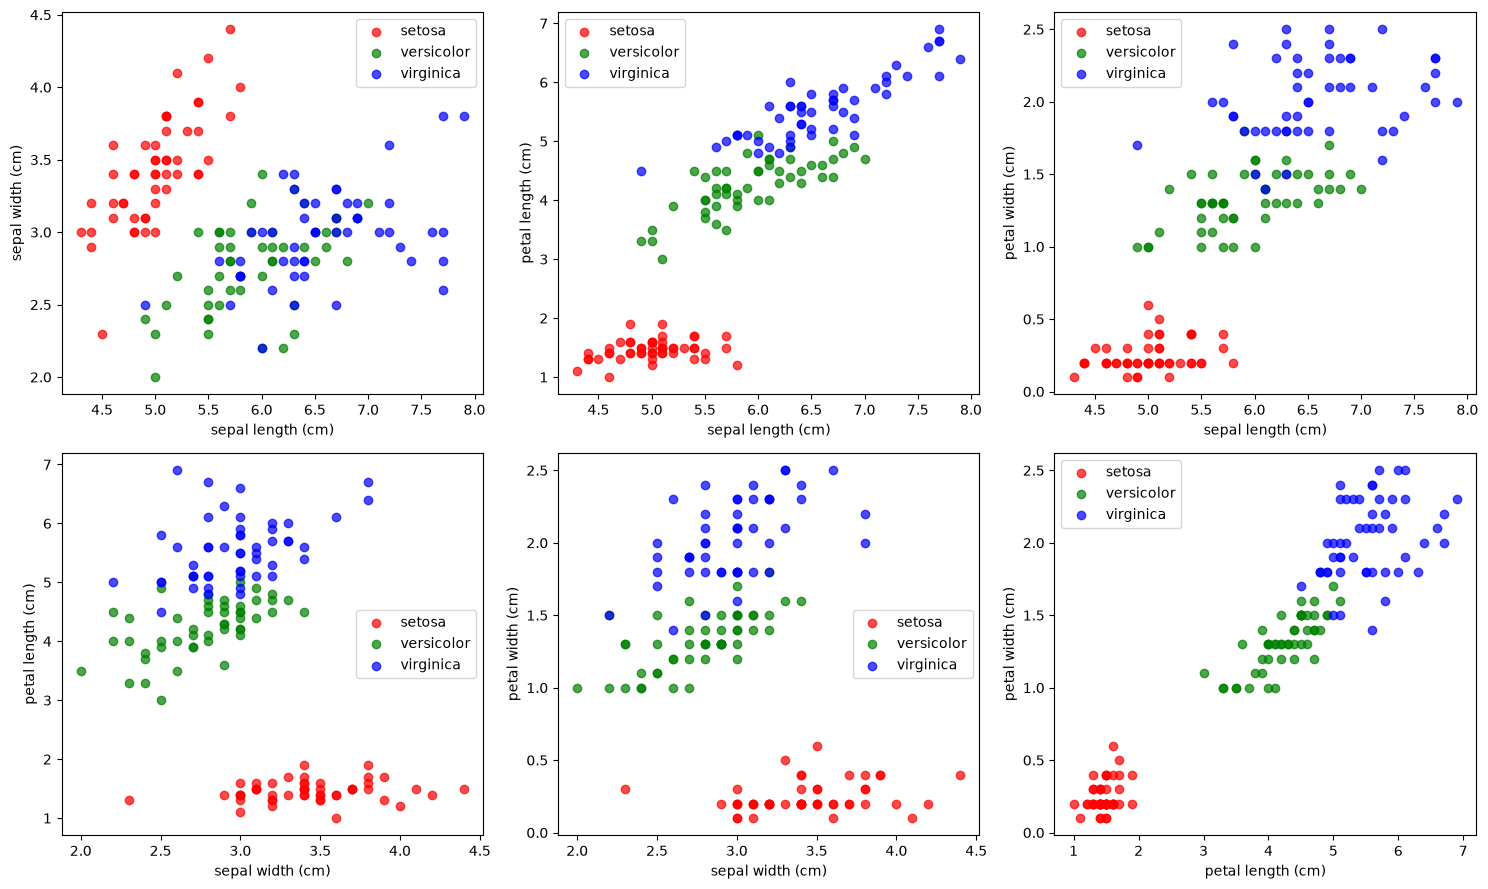

In [10]:
import matplotlib.pyplot as plt
from itertools import combinations

paires = list(combinations(range(4), 2))
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (i, j) in zip(axes.ravel(), paires):
    for c, couleur in zip(range(3), ["red", "green", "blue"]):
        ax.scatter(X[y == c, i], X[y == c, j], c=couleur,
                   label=iris.target_names[c], alpha=0.7)
    ax.set_xlabel(iris.feature_names[i])
    ax.set_ylabel(iris.feature_names[j])
    ax.legend()

plt.tight_layout()
plt.show()

## Analyse des graphiques
La classe setosa est séparable sur tous les graphiques, y compris sépales, même si l'écart y est plus faible. La difficulté principale est de séparer versicolor et virginica, qui se chevauchent plus ou moins selon les variables choisies.
Le graphique longueur du sépale / largeur du sépale est le moins bon : versicolor et virginica y sont fortement mélangées, car ces deux espèces ont des sépales de tailles très proches.
## Meilleure visualisation
La meilleure visualisation est longueur du pétale / largeur du pétale. Sur ce graphique, les trois classes forment trois groupes bien distincts : setosa est complètement isolée en bas à gauche (petits pétales), versicolor occupe la zone intermédiaire et virginica la zone des grands pétales. Le chevauchement entre versicolor et virginica est très faible (seulement quelques points à la frontière).
On peut justifier ce choix ainsi : les variables liées aux pétales sont celles qui varient le plus d'une espèce à l'autre, alors qu'elles varient peu à l'intérieur d'une même espèce. Ce sont donc les variables les plus discriminantes. Ce constat annonce la partie D : on cherchera à construire automatiquement des axes qui séparent au mieux les données.

# D) Réduction de dimensions et visualisation de données
La base Iris a 4 variables, ce qui empêche de la représenter dans un seul graphique. En partie C, on a contourné le problème en traçant les variables deux par deux, mais chaque graphique ne montre qu'une partie de l'information. Les méthodes de réduction de dimension permettent de construire de nouveaux axes, combinaisons des variables d'origine, qui résument l'essentiel de l'information en seulement 2 dimensions.
L'ACP (Analyse en Composantes Principales, PCA en anglais) est une méthode non supervisée : elle n'utilise pas les classes et cherche les directions où les données ont la plus grande variance.
L'ADL (Analyse Discriminante Linéaire, LDA en anglais) est une méthode supervisée : elle utilise les étiquettes de classe et cherche les directions qui séparent le mieux les classes, c'est-à-dire qui maximisent la variance entre les classes tout en minimisant la variance à l'intérieur de chaque classe.

## 1) Import des méthodes PCA et LDA

In [11]:
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA

## 2) Aide des fonctions et application sur Iris

## Application

In [12]:
pca = PCA(n_components=2)
IrisPCA = pca.fit_transform(X)

lda = LDA(n_components=2)
IrisLDA = lda.fit(X, y).transform(X)

print(IrisPCA.shape, IrisLDA.shape)        # (150, 2) (150, 2)
print("Variance expliquée ACP :", pca.explained_variance_ratio_)
print("Variance expliquée ADL :", lda.explained_variance_ratio_)

(150, 2) (150, 2)
Variance expliquée ACP : [0.92461872 0.05306648]
Variance expliquée ADL : [0.9912126 0.0087874]


Les données passent de 4 à 2 dimensions : `IrisPCA` et `IrisLDA` ont chacune 150 lignes et 2 colonnes.
Pour l'ACP, la variance expliquée vaut environ [0,925 ; 0,053] : le premier axe résume à lui seul près de 92,5 % de la variance des données, et les deux axes ensemble environ 97,8 %. On perd donc très peu d'information en passant de 4 à 2 dimensions.
Pour l'ADL, le ratio vaut environ [0,991 ; 0,009] : il ne s'agit pas ici de la variance totale, mais de la part de la séparation entre classes portée par chaque axe. Le premier axe discriminant suffit presque à lui seul à séparer les trois espèces.

## 3) Visualisation des nouveaux axes

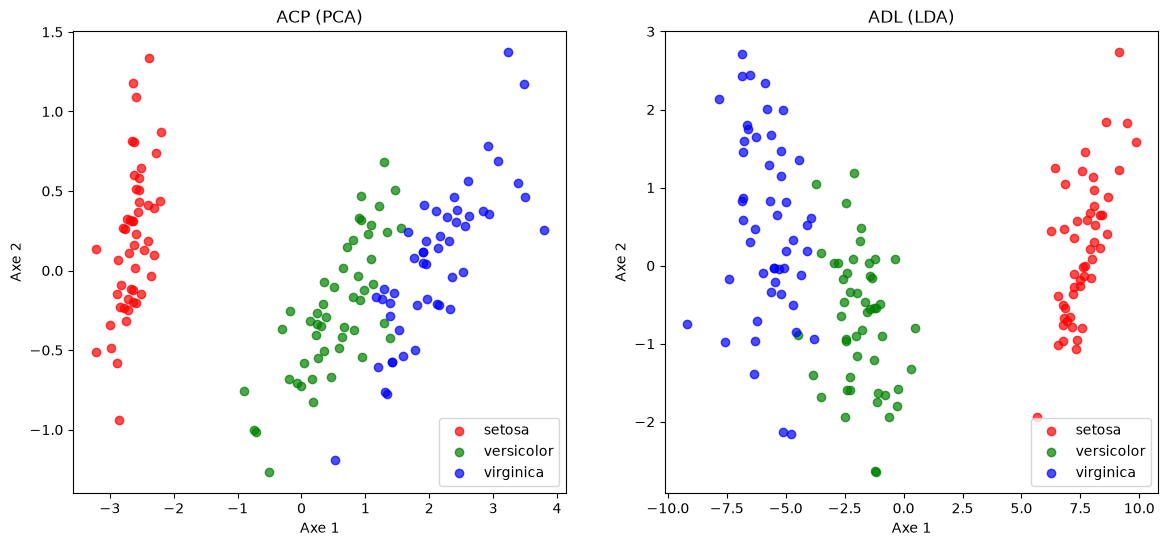

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
donnees = [(IrisPCA, "ACP (PCA)"), (IrisLDA, "ADL (LDA)")]

for ax, (Z, titre) in zip(axes, donnees):
    for c, couleur in zip(range(3), ["red", "green", "blue"]):
        ax.scatter(Z[y == c, 0], Z[y == c, 1], c=couleur,
                   label=iris.target_names[c], alpha=0.7)
    ax.set_title(titre)
    ax.set_xlabel("Axe 1")
    ax.set_ylabel("Axe 2")
    ax.legend()

plt.show()

## Différences observées
Sur la projection ACP, la classe setosa est bien isolée, mais versicolor et virginica restent proches et se chevauchent légèrement. Les points sont très étalés le long de l'axe 1 et peu le long de l'axe 2, ce qui est cohérent avec la variance expliquée (92,5 % sur le premier axe).
Sur la projection ADL, les trois classes forment des groupes plus compacts et mieux séparés. Le chevauchement entre versicolor et virginica est nettement réduit, et la séparation se fait essentiellement le long de l'axe 1.
## Explication du raisonnement
Cette différence vient de l'objectif de chaque méthode.
L'ACP ignore les classes. Elle cherche simplement les directions où les données sont le plus dispersées. Or une direction de grande dispersion n'est pas forcément une direction qui sépare bien les classes : la variance peut venir des différences à l'intérieur d'une même espèce. Si l'ACP sépare quand même bien setosa, c'est parce que, sur Iris, la plus grande source de variance est justement la différence de taille des pétales entre setosa et les deux autres espèces.
L'ADL, elle, utilise les étiquettes de classe. Elle cherche les directions qui éloignent le plus les centres des classes les uns des autres tout en gardant chaque classe la plus resserrée possible. Elle est donc directement optimisée pour la séparation des classes, ce qui explique une meilleure visualisation pour la classification.
En résumé, l'ACP est adaptée pour résumer et compresser les données sans connaître les classes, tandis que l'ADL est adaptée pour discriminer des classes connues. Il faut aussi garder en tête que l'ADL, utilisant les classes, n'est applicable que sur des données étiquetées.
On peut enfin faire le lien avec la partie A : l'ACP étant basée sur la variance, elle est sensible à l'échelle des variables. Sur Iris, toutes les variables sont en centimètres donc ce n'est pas gênant, mais sur des données aux unités différentes, il faudrait standardiser les données avant l'ACP, sinon les variables aux grandes valeurs domineraient les composantes principales.